In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv(
    os.path.join("..", "data", "raw", "SHED 2025 CSV Raw.csv"),
    low_memory=False
)

target = df["pay_casheqv"].map({"Yes": 0, "No": 1})  # 1 = fragile
sample_weight = df["weight"]

print(df.shape)
print(target.value_counts())

(12934, 815)
pay_casheqv
0    8398
1    4536
Name: count, dtype: int64


In [3]:
split = pd.read_csv("../outputs/tables/train_test_split.csv").set_index("index")["split"]

train_idx = split.index[split == "train"]
test_idx = split.index[split == "test"]

print(len(train_idx), len(test_idx))

10347 2587


In [4]:
categorical_features = [
    "B2", "EF1", "ppinc7", "FD3", "E2B",
    "A6", "ppeduc5", "GH1", "I9", "ppemploy"
]
numeric_features = ["ppage", "pphhsize"]
near_target_features = ["B2", "EF1"]

features = categorical_features + numeric_features

In [5]:
X = df[features].copy()

for col in categorical_features:
    X[col] = X[col].fillna("NOT_ASKED").astype("category")

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = target.loc[train_idx], target.loc[test_idx]
w_train, w_test = sample_weight.loc[train_idx], sample_weight.loc[test_idx]

print(X_train.shape, X_test.shape)
print(X_train.dtypes)

(10347, 12) (2587, 12)
B2          category
EF1         category
ppinc7      category
FD3         category
E2B         category
A6          category
ppeduc5     category
GH1         category
I9          category
ppemploy    category
ppage          int64
pphhsize       int64
dtype: object


In [6]:
xgb_default = XGBClassifier(
    enable_categorical=True,  # read the category columns directly
    tree_method="hist",       # required when using categories
    random_state=42           # same results every time you run it
)

xgb_default.fit(X_train, y_train, sample_weight=w_train)

prob_default = xgb_default.predict_proba(X_test)[:, 1]
print(prob_default[:10])

[0.6997484  0.21059282 0.0248321  0.01188888 0.04371814 0.01154575
 0.01178818 0.01368036 0.8492176  0.0138448 ]


In [8]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss
)

def evaluate(name, y_true, prob, weights, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Model": name,
        "ROC_AUC": roc_auc_score(y_true, prob, sample_weight=weights),
        "PR_AUC": average_precision_score(y_true, prob, sample_weight=weights),
        "Brier": brier_score_loss(y_true, prob, sample_weight=weights),
        "Accuracy": accuracy_score(y_true, pred, sample_weight=weights),
        "Precision": precision_score(y_true, pred, sample_weight=weights, zero_division=0),
        "Recall": recall_score(y_true, pred, sample_weight=weights),
        "F1": f1_score(y_true, pred, sample_weight=weights),
    }

pd.DataFrame([evaluate("XGBoost (default)", y_test, prob_default, w_test)]).round(3)

,Model,ROC_AUC,PR_AUC,Brier,Accuracy,Precision,Recall,F1
0,XGBoost (default),0.876,0.802,0.138,0.814,0.752,0.742,0.747


In [10]:
from itertools import product
from sklearn.model_selection import StratifiedKFold

param_grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [200, 500],
    "min_child_weight": [1, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for depth, lr, n_trees, mcw in product(*param_grid.values()):
    fold_auc, fold_brier = [], []

    for fit_idx, val_idx in cv.split(X_train, y_train):
        model = XGBClassifier(
            enable_categorical=True, tree_method="hist", random_state=42,
            max_depth=depth, learning_rate=lr,
            n_estimators=n_trees, min_child_weight=mcw,
        )
        model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx],
                  sample_weight=w_train.iloc[fit_idx])

        prob = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_auc.append(roc_auc_score(y_train.iloc[val_idx], prob,
                                      sample_weight=w_train.iloc[val_idx]))
        fold_brier.append(brier_score_loss(y_train.iloc[val_idx], prob,
                                           sample_weight=w_train.iloc[val_idx]))

    cv_results.append({
        "max_depth": depth, "learning_rate": lr,
        "n_estimators": n_trees, "min_child_weight": mcw,
        "cv_ROC_AUC": np.mean(fold_auc), "cv_Brier": np.mean(fold_brier),
    })

cv_results = pd.DataFrame(cv_results).sort_values("cv_Brier")
cv_results.head(10).round(4)

,max_depth,learning_rate,n_estimators,min_child_weight,cv_ROC_AUC,cv_Brier
9,3,0.03,200,5,0.9047,0.1175
8,3,0.03,200,1,0.9045,0.1175
1,2,0.03,200,5,0.9045,0.1177
0,2,0.03,200,1,0.9045,0.1177
3,2,0.03,500,5,0.9041,0.1178
2,2,0.03,500,1,0.9040,0.1179
17,4,0.03,200,5,0.9041,0.1180
5,2,0.10,200,5,0.9035,0.1181
4,2,0.10,200,1,0.9035,0.1182
16,4,0.03,200,1,0.9035,0.1183


In [11]:
best = cv_results.iloc[0]
best_params = {
    "max_depth": int(best["max_depth"]),
    "learning_rate": float(best["learning_rate"]),
    "n_estimators": int(best["n_estimators"]),
    "min_child_weight": int(best["min_child_weight"]),
}
print(best_params)

xgb_tuned = XGBClassifier(
    enable_categorical=True, tree_method="hist", random_state=42,
    **best_params
)
xgb_tuned.fit(X_train, y_train, sample_weight=w_train)
prob_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

{'max_depth': 3, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_weight': 5}


In [12]:
results = pd.DataFrame([
    {"Model": "Logistic Regression (notebook 04)",
     "ROC_AUC": 0.899, "PR_AUC": 0.836, "Brier": 0.120},
    evaluate("XGBoost (default)", y_test, prob_default, w_test),
    evaluate("XGBoost (tuned)", y_test, prob_tuned, w_test),
])
results[["Model", "ROC_AUC", "PR_AUC", "Brier"]].round(3)

,Model,ROC_AUC,PR_AUC,Brier
0,Logistic Regression (notebook 04),0.899,0.836,0.120
1,XGBoost (default),0.876,0.802,0.138
2,XGBoost (tuned),0.900,0.834,0.120


In [13]:
def weighted_calibration(y_true, prob, weights, n_bins=10):
    y_true, prob, weights = map(np.asarray, (y_true, prob, weights))
    edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(np.digitize(prob, edges) - 1, 0, n_bins - 1)

    rows = []
    for b in range(n_bins):
        in_bin = bin_ids == b
        if in_bin.any():
            rows.append({
                "mean_predicted": np.average(prob[in_bin], weights=weights[in_bin]),
                "observed_rate": np.average(y_true[in_bin], weights=weights[in_bin]),
                "n": int(in_bin.sum()),
            })
    return pd.DataFrame(rows)

calibration_tuned = weighted_calibration(y_test, prob_tuned, w_test)
calibration_tuned.round(3)

,mean_predicted,observed_rate,n
0,0.049,0.050,986
1,0.139,0.159,306
2,0.245,0.195,200
3,0.347,0.355,117
4,0.452,0.438,96
5,0.550,0.512,140
6,0.649,0.699,116
7,0.754,0.778,179
8,0.854,0.885,218
9,0.939,0.901,229


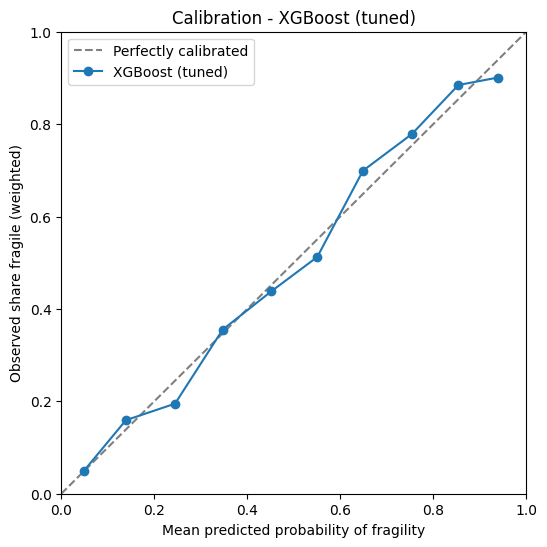

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.plot(calibration_tuned["mean_predicted"], calibration_tuned["observed_rate"],
        marker="o", label="XGBoost (tuned)")
ax.set_xlabel("Mean predicted probability of fragility")
ax.set_ylabel("Observed share fragile (weighted)")
ax.set_title("Calibration - XGBoost (tuned)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

os.makedirs("../outputs/figures", exist_ok=True)
fig.savefig("../outputs/figures/calibration_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
reduced_features = [f for f in features if f not in near_target_features]

xgb_reduced = XGBClassifier(
    enable_categorical=True, tree_method="hist", random_state=42,
    **best_params
)
xgb_reduced.fit(X_train[reduced_features], y_train, sample_weight=w_train)
prob_reduced = xgb_reduced.predict_proba(X_test[reduced_features])[:, 1]

results = pd.DataFrame([
    {"Model": "Logistic Regression (notebook 04)",
     "ROC_AUC": 0.899, "PR_AUC": 0.836, "Brier": 0.120},
    {"Model": "Logistic Regression (no B2/EF1)",
     "ROC_AUC": 0.867, "PR_AUC": 0.792, "Brier": 0.140},
    evaluate("XGBoost (default)", y_test, prob_default, w_test),
    evaluate("XGBoost (tuned)", y_test, prob_tuned, w_test),
    evaluate("XGBoost (tuned, no B2/EF1)", y_test, prob_reduced, w_test),
])

results.to_csv("../outputs/tables/xgboost_results.csv", index=False)
results[["Model", "ROC_AUC", "PR_AUC", "Brier"]].round(3)

,Model,ROC_AUC,PR_AUC,Brier
0,Logistic Regression (notebook 04),0.899,0.836,0.120
1,Logistic Regression (no B2/EF1),0.867,0.792,0.140
2,XGBoost (default),0.876,0.802,0.138
3,XGBoost (tuned),0.900,0.834,0.120
4,"XGBoost (tuned, no B2/EF1)",0.869,0.796,0.138


## Summary

Survey-weighted results on the held-out test set (2,587 respondents), using the same 12 features and split as `04_logistic_baseline`:

| Model | ROC AUC | PR AUC | Brier |
|---|---|---|---|
| Logistic Regression | 0.899 | 0.836 | 0.120 |
| XGBoost (default) | 0.876 | 0.802 | 0.138 |
| XGBoost (tuned) | 0.900 | 0.834 | 0.120 |
| Logistic Regression (no B2/EF1) | 0.867 | 0.792 | 0.140 |
| XGBoost (tuned, no B2/EF1) | 0.869 | 0.796 | 0.138 |

- Default XGBoost overfit. Tuning with 5-fold weighted cross-validation on the training set (ranked by Brier) chose shallow trees: max_depth=3, learning_rate=0.03, 200 trees, min_child_weight=5.
- Tuned XGBoost ties logistic regression. With 12 mostly categorical features there are few nonlinear patterns or interactions left for boosting to exploit.
- XGBoost is well calibrated (every bin within ~5 points of the diagonal), so no recalibration was needed. It is slightly overconfident in the top bin (predicted 94%, observed 90%).
- Removing B2/EF1 costs both models about 0.03 ROC AUC, so both rely on them to a similar degree.
- Next: train on the full feature set from `03_preprocessing`, where boosting is more likely to outperform logistic regression.